# Linear Spectral Unmixing

*Section 7 — Spectral analysis, notebook 3 of 3.* Previous: `07_spectral_analysis/02_hyperspectral_image_analysis`. Next: `08_hydrology/01_hydrological_analysis`.

**You will learn:**
- how to explore the feature space with `plot_2d_img_histogram` and define endmembers, manually and with the pixel purity index (PPI);
- how to extract average endmember spectra from polygons and plot them (`plot_spectra`, `plot_endmembers`);
- how to run unconstrained, non-negative and fully constrained linear unmixing;
- how to predict reflectance from the abundances and calculate the unmixing error;
- how to compare the results side by side with `create_map_panels`.

**Before you start:** notebook 2 introduces the HyMap image, spectral smoothing and the MNF transformation, which are used again here (this notebook recalculates its own copies, so you do not need to have run notebook 2).

**Data:** `../data/hymap_injune_subset.tif` (HyMap, 126 bands, reflectance x 10,000), `../data/hymap_wavelengths.json` and `../data/hymap_ppi_endmembers.geojson` (endmember polygons). Outputs are written to `outputs/unmixing/`.

**Run time:** about 3 minutes.

## Background

Spectral unmixing assumes that the spectral response of a pixel is the linear product of a series of endmembers from which we can define the proportions associated with a pixel (i.e., unmix the mixed pixels). To do this we need to define the endmembers without our feature space, these are essentially simple training samples for a classifier but rather than taking in the full variation of the class want to just identify the ‘end member’ (i.e., the most spectrally ‘pure’ example of that class).


## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense. 

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_



# 1. Import Modules

In [1]:
import os

import geopandas
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy
import rsgispy
import rsgispy.imagecalc.calcindices
import rsgispy.imagecalc.maths
import rsgispy.imagecalc.rescale
import rsgispy.imagespectral.endmembers
import rsgispy.imagespectral.preprocessing
import rsgispy.imagespectral.spectra as spectra
import rsgispy.imagespectral.transforms
import rsgispy.imagespectral.unmixing
import rsgispy.imageutils.arrays
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.masking
import rsgispy.imageutils.metadata
import rsgispy.imageutils.stats
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
import rsgispy.vector.create
import rsgispy.zonalstats
import rsgispy.zonalstats.polygon

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

# 2. Define Input Files and Output Directory

In [2]:
# The input image is only read, so it is used directly from the data directory.
input_img = "../data/hymap_injune_subset.tif"

out_dir = os.path.join("outputs", "unmixing")
os.makedirs(out_dir, exist_ok=True)

# Read the HyMap metadata for wavelength info.
hymap_meta_file = "../data/hymap_wavelengths.json"
hymap_metadata = rsgispy.tools.jsonio.read_json_to_dict(hymap_meta_file)

# 3. Defining Endmembers

## 3.1 Plotting Feature Space

It is useful to plot the feature space as endmembers are often found on the edges of the feature space to undertaking what values are on the edges of the feature space can allow you to look at your imagery and interpret features which might be candidate endmembers.

`rsgispy.tools.plotting.plot_2d_img_histogram` calculates the 2D histogram of two image bands (block by block, with `rsgispy.imagecalc.stats.get_img_2d_histogram`) and plots it: the colour is the proportion of the valid pixels in each bin, on a logarithmic scale so the sparse bins at the edges of the feature space are visible, and empty bins are white. Only the pixels within `x_range` and `y_range` in both bands are counted (which excludes the no data value, 0). The image values are reflectance x 10,000, so `val_scale=100` plots the reflectance in %.

**RSGISLib users:** this replaces `rsgislib.imagecalc.get_2d_img_histogram`, which wrote the histogram to an image file; `get_img_2d_histogram` returns the histogram as a NumPy array.

  0%|          | 0/33 [00:00<?, ?it/s]

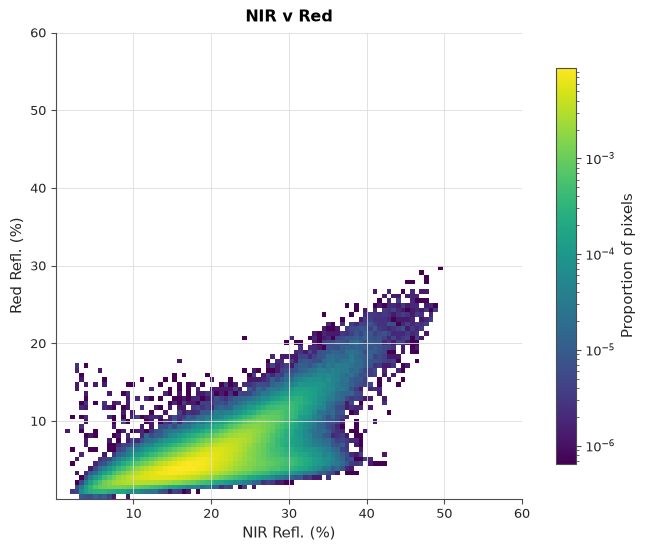

In [3]:
# Plot of NIR v Red (bands 42 and 13)
fig, ax = rsgispy.tools.plotting.plot_2d_img_histogram(
    input_img,
    x_band=42,
    y_band=13,
    bins=100,
    x_range=(1, 6000),
    y_range=(1, 6000),
    val_scale=100,
    title="NIR v Red",
    x_label="NIR Refl. (%)",
    y_label="Red Refl. (%)",
)

  0%|          | 0/33 [00:00<?, ?it/s]

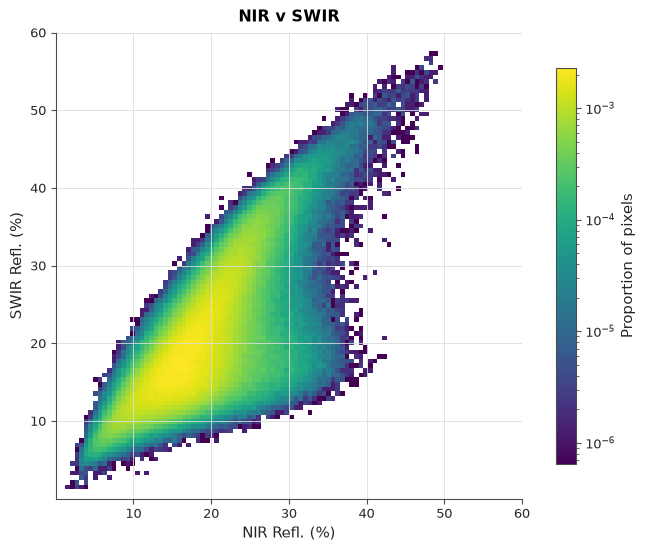

In [4]:
# Plot of NIR v SWIR (bands 42 and 81)
fig, ax = rsgispy.tools.plotting.plot_2d_img_histogram(
    input_img,
    x_band=42,
    y_band=81,
    bins=100,
    x_range=(1, 6000),
    y_range=(1, 6000),
    val_scale=100,
    title="NIR v SWIR",
    x_label="NIR Refl. (%)",
    y_label="SWIR Refl. (%)",
)

  0%|          | 0/33 [00:00<?, ?it/s]

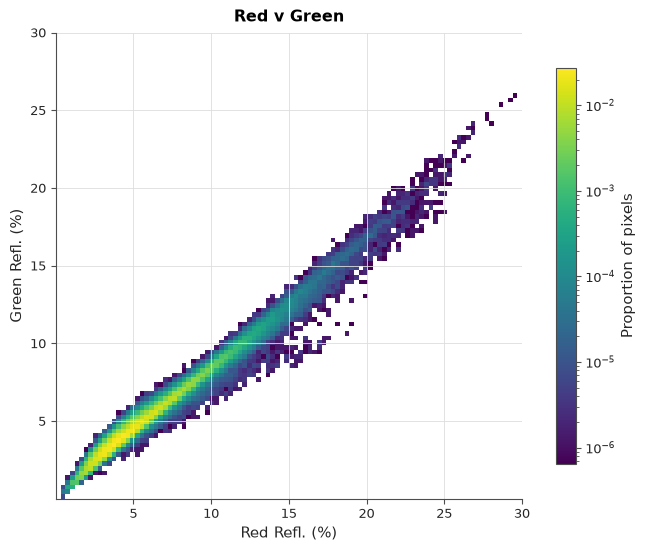

In [5]:
# Plot of Red v Green (bands 13 and 9)
fig, ax = rsgispy.tools.plotting.plot_2d_img_histogram(
    input_img,
    x_band=13,
    y_band=9,
    bins=100,
    x_range=(1, 3000),
    y_range=(1, 3000),
    val_scale=100,
    title="Red v Green",
    x_label="Red Refl. (%)",
    y_label="Green Refl. (%)",
)

## 3.2 Manually Defined Endmembers

Often, end members are defined by manually by annotating the image through user interpretation of the scene. An example is given below where the coordinates of pixels for the following classes have been identified:

 1. Photosynthetic Vegetation
 2. Soil / bare ground
 3. Shadow


*You may wish to edit these locations and compare these spectra with those derived from the spectrally smoothed HyMap image.*


In [6]:
# Coordinates of endmember pixels (identified in QGIS):
# 0: Photosynthetic pixel
# 1: Soil / bare ground pixel
# 2: Shadow pixel
x_coords = numpy.array([546933.6, 547573.3, 547903.6])
y_coords = numpy.array([7165115.7, 7164588.9, 7161428.6])

# Get the image pixel coordinates for those pixels:
x_pxl_coords, y_pxl_coords = rsgispy.imageutils.metadata.get_img_pxl_coords(
    input_img, x_coords, y_coords
)
print(x_pxl_coords)
print(y_pxl_coords)

[143 389 517]
[ 697  900 2116]


In [7]:
# Get the image pixel values for endmembers
photo_pxl_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[0]), y_pxl_coord=int(y_pxl_coords[0])
)
bare_pxl_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[1]), y_pxl_coord=int(y_pxl_coords[1])
)
shadow_pxl_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[2]), y_pxl_coord=int(y_pxl_coords[2])
)

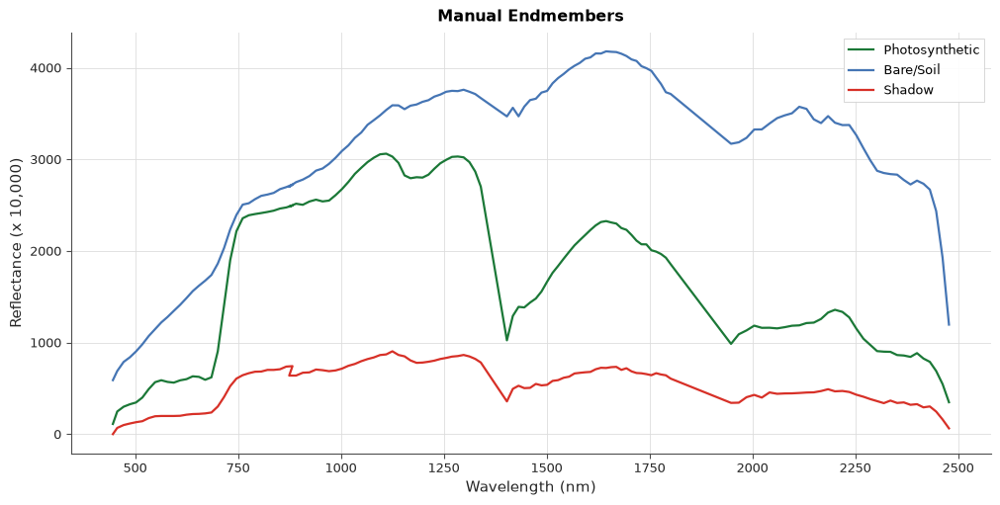

In [8]:
# The endmember colours used in the plots and maps below.
em_colours = {"Photosynthetic": "#1B7837", "Bare/Soil": "#4575B4", "Shadow": "#D73027"}

# Plot Endmembers
fig, ax = spectra.plot_spectra(
    {"Photosynthetic": photo_pxl_vals, "Bare/Soil": bare_pxl_vals, "Shadow": shadow_pxl_vals},
    wavelengths=hymap_metadata["wavelength"],
    colours=list(em_colours.values()),
    title="Manual Endmembers",
    y_label="Reflectance (x 10,000)",
    figsize=(10, 5),
)

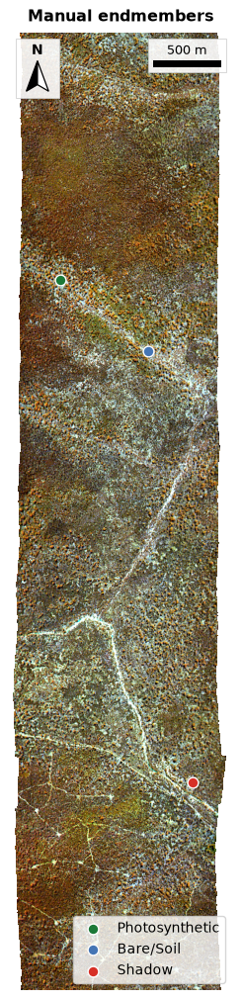

In [9]:
# Plot the Endmember locations on a map
# Visualise with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Manual endmembers",
        )
    ],
    figsize=(5, 10),
)
for (em_name, em_clr), x_coord, y_coord in zip(em_colours.items(), x_coords, y_coords):
    axs[0].scatter(x_coord, y_coord, label=em_name, color=em_clr, edgecolor="white", s=60, zorder=5)
leg = axs[0].legend(loc="lower right")

## 3.3 Pixel Purity Index (PPI)

There is a large literature of methods to find endmembers within imagery, in terms of spectral unmixing it is the largest area of active research. One of the simplest approaches in ‘pixel purity index’ (PPI) which aims to identify pixels in the image which are thought to be ‘pure’ from which you can then draw a set of end members, as done above.

PPI is an iterative method which randomly rotates the axes of the data and counting the number of times a pixel is found 'on the edge' of the feature space. The output image contains this count and therefore would need thresholding to identified defined regions.

The most common way of running a PPI analysis with hyperspectral data is to use the output from a MNF, in this case we will use the MNF transformation reduced to the top 5 components. Reducing the number of dimensions (i.e., bands) significantly speeds up the calculation of the PPI. 

This analysis is run below and will first normalise the 5 MNF components so they all have a range between 1-100, with 0 being the no data value.

**RSGISLib users:** `normalise_img_pxl_vals` is now in `rsgispy.imagecalc.rescale` and takes a `method` name (`"linear"` is a min-max stretch) rather than a stretch type constant.

In [10]:
# Calculate the MNF result
mnf_img = os.path.join(out_dir, "hymap_injune_subset_mnf.tif")

# As we know from the PCA we only need 5 components.
# The output no data value is -9999.
rsgispy.imagespectral.transforms.calc_mnf(
    input_img,
    mnf_img,
    n_components=5,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
    calc_stats=True,
)

# Normalise the MNF results to 1-100 with 0 as the no data value.
mnf_norm_img = os.path.join(out_dir, "hymap_injune_subset_mnf_norm.tif")
rsgispy.imagecalc.rescale.normalise_img_pxl_vals(
    mnf_img,
    mnf_norm_img,
    method="linear",
    out_min=1,
    out_max=100,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=-9999,
    out_no_data_val=0,
)
rsgispy.imageutils.stats.pop_img_stats(mnf_norm_img, no_data_val=0, calc_pyramids=True)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

In [11]:
ppi_img = os.path.join(out_dir, "hymap_injune_subset_mnf_norm_ppi.tif")
# A random seed is set so the result is reproducible; change it
# (or set it to None) to see how the result varies.
rsgispy.imagespectral.endmembers.calc_ppi(
    mnf_norm_img,
    ppi_img,
    n_skewers=1000,
    lower_thres=1,
    upper_thres=2,
    gain=1,
    rnd_seed=42,
    gdalformat="GTIFF",
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

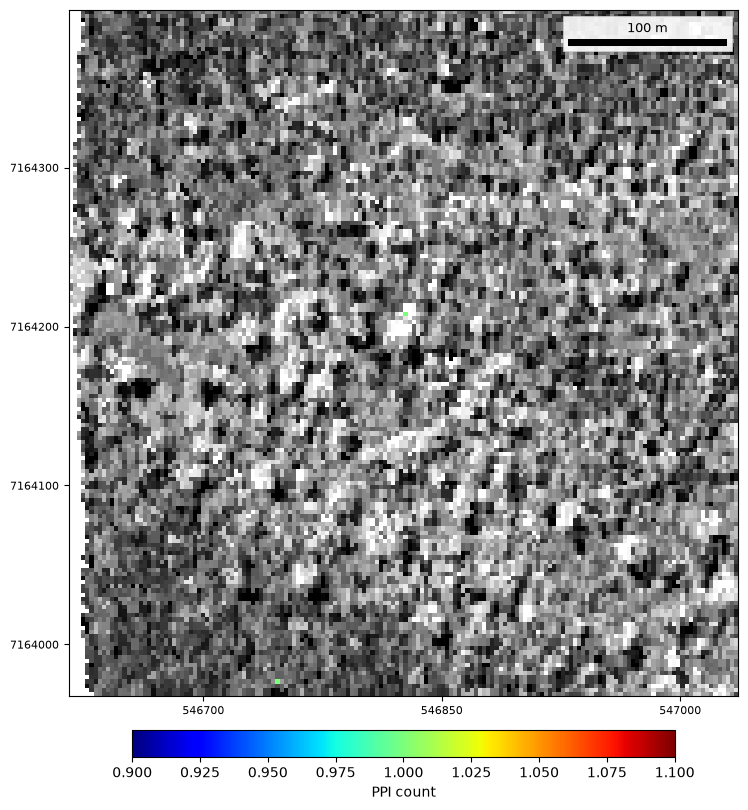

In [12]:
sub_bbox = [546614, 547036, 7163968, 7164398]


# Visualise PPI - need to zoom in to region for it to be visible
img_ppi_data, img_ppi_coords = rsgispy.tools.plotting.get_raster_mpl_imshow(
    ppi_img, bands=[1], bbox=sub_bbox
)

# Pixels with a count of 0 (below vmin=1) are transparent.
cmap = matplotlib.colormaps["jet"].with_extremes(under=(1, 1, 1, 0))
c_norm = mcolors.Normalize(vmin=1, vmax=numpy.max(img_ppi_data))

# Create the matplotlib figure
fig, ax1 = plt.subplots(1, 1, figsize=(10, 11))

# Plot the NIR band (32) of the original image in grey, so the PPI counts stand out
grey_im = rsgispy.mapping.raster.create_raster_img_map(
    ax1,
    input_img,
    img_bands=[32],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=sub_bbox,
    show_scale_bar=True,
)

im = ax1.imshow(img_ppi_data, cmap=cmap, norm=c_norm, extent=img_ppi_coords, zorder=2)
cbar = fig.colorbar(im, ax=ax1, orientation="horizontal", shrink=0.7, pad=0.04)
cbar.set_label("PPI count")

You have a count of the number of times each pixel was identified as an 'edge' pixel. The higher than count the more extreme the endmember. However, we want the same endmembers as manually selected:

 1. Photosynthetic Vegetation
 2. Soil / bare ground
 3. Shadow

and, we want just one endmember for each 'class'. Therefore, we need to use the PPI output to guide this selection. One option would be to just draw three polygons using the PPI output as a reference. Alternatively, we could run some rules and further layers of information to reduce the number of options to select between. 

Some simple rules are shown below using the NDVI to separate photosynthesis vegetation and brightness to separate the shadow and bare soil regions. The script will output the regions are separate vector layer for review to decide the 'best' endmember to use. For this analysis we will just visually select some features but we will also use zonal statistics to populate the PPI count to the polygons to help rank regions further.

**RSGISLib users:** `calc_ndvi` and `calc_brightness` are replaced by a single call to `rsgispy.imagecalc.calcindices.calc_indices`, which writes both indices to one image (band 1 = NDVI, band 2 = Brightness). Here `in_gain=10000` converts the image values to reflectance (0-1), so brightness is the mean blue, green and red reflectance; RSGISLib's `calc_brightness` divided by 1000, so the brightness thresholds below are on a different scale from the RSGISLib version of this tutorial (and the shadow threshold has been raised to 0.02, as the new PPI result had no candidate pixels darker than 0.01). The candidate masks get a class name and colour with `set_thematic_classes` rather than a raster attribute table.

In [13]:
# Output Vector Layer
ppi_endmembers_vec = os.path.join(out_dir, "hymap_injune_subset_ppi_endmembers.gpkg")
if os.path.exists(ppi_endmembers_vec):
    os.remove(ppi_endmembers_vec)

# Calculate the NDVI (band 1) and brightness (band 2)
# HyMap bands: 2 = blue, 9 = green, 13 = red and 42 = NIR.
indices_img = os.path.join(out_dir, "hymap_injune_subset_ndvi_bright.tif")
rsgispy.imagecalc.calcindices.calc_indices(
    input_img,
    indices_img,
    band_names={2: "blue", 9: "green", 13: "red", 42: "nir"},
    indices=["NDVI", "Brightness"],
    in_gain=10000,
    no_data_val=0,
    gdalformat="GTIFF",
    calc_stats=True,
)

ppi_band = rsgispy.imagecalc.maths.BandDefn("ppi", ppi_img, 1)
ndvi_band = rsgispy.imagecalc.maths.BandDefn("ndvi", indices_img, 1)
bright_band = rsgispy.imagecalc.maths.BandDefn("bright", indices_img, 2)

# The rules defining potential endmember pixels for each class:
# name: (class name, colour, band maths expression, band definitions)
ppi_candidates = {
    "phveg": (
        "Photosynthetic",
        em_colours["Photosynthetic"],
        "(ppi > 1)&&(ndvi>0.5)&&(bright>0.02)?1:0",
        [ppi_band, ndvi_band, bright_band],
    ),
    "shadow": ("Shadow", em_colours["Shadow"], "(ppi > 1)&&(bright<0.02)?1:0", [ppi_band, bright_band]),
    "bare": ("Bare/Soil", em_colours["Bare/Soil"], "(ppi > 1)&&(bright>0.1)?1:0", [ppi_band, bright_band]),
}

for cand_name, (cls_name, cls_clr, exp, band_defns) in ppi_candidates.items():
    # Use band_maths to define the potential endmember pixels (1).
    cand_img = os.path.join(out_dir, "hymap_injune_subset_ppi_{}.tif".format(cand_name))
    rsgispy.imagecalc.maths.band_maths(
        cand_img, exp, band_defns, gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT
    )
    # Mark it as thematic with a class name and colour, and calculate the
    # statistics and pyramids.
    rsgispy.imageutils.colourtable.set_thematic_classes(cand_img, {1: (cls_name, cls_clr)})

    # Vectorise the candidate pixels to a layer in ppi_endmembers_vec.
    rsgispy.vector.create.polygonise_raster_to_vec_lyr(
        cand_img,
        out_vec_file=ppi_endmembers_vec,
        out_vec_lyr="hymap_injune_subset_ppi_{}".format(cand_name),
        out_format="GPKG",
        img_band=1,
        mask_img=cand_img,
        mask_band=1,
        replace_file=False,
        replace_lyr=True,
    )

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

In [14]:
# Add the median PPI count of the pixels within each polygon to the
# layers (the vector file is updated in place).
for vec_lyr in [
    "hymap_injune_subset_ppi_phveg",  # photosynthetic veg
    "hymap_injune_subset_ppi_shadow",  # shadow
    "hymap_injune_subset_ppi_bare",  # bare/soil
]:
    rsgispy.zonalstats.polygon.calc_zonal_band_stats_file(
        vec_file=ppi_endmembers_vec,
        vec_lyr=vec_lyr,
        input_img=ppi_img,
        img_band=1,
        min_thres=1,
        max_thres=200,
        out_no_data_val=0,
        median_field="ppi_count",
    )

  0%|          | 0/166 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/96 [00:00<?, ?it/s]

In [15]:
# Show the number of candidate regions and the highest PPI counts in each layer.
for vec_lyr in [
    "hymap_injune_subset_ppi_phveg",
    "hymap_injune_subset_ppi_shadow",
    "hymap_injune_subset_ppi_bare",
]:
    cand_gdf = geopandas.read_file(ppi_endmembers_vec, layer=vec_lyr)
    print(
        "{}: {} regions, top PPI counts: {}".format(
            vec_lyr, len(cand_gdf), cand_gdf["ppi_count"].nlargest(5).tolist()
        )
    )

hymap_injune_subset_ppi_phveg: 166 regions, top PPI counts: [74.0, 68.0, 29.0, 28.0, 25.0]
hymap_injune_subset_ppi_shadow: 11 regions, top PPI counts: [16.0, 7.0, 4.0, 4.0, 4.0]
hymap_injune_subset_ppi_bare: 96 regions, top PPI counts: [88.0, 64.0, 63.0, 62.0, 55.0]


## 3.4 Plot PPI Endmembers

In [16]:
# Coordinates of endmember pixels (identified in QGIS):
# 0: Photosynthetic pixel
# 1: Soil / bare ground pixel
# 2: Shadow pixel
x_coords = numpy.array([546999, 547412, 546749])
y_coords = numpy.array([7161936, 7161561, 7166579])

# Get the image pixel coordinates for those pixels:
x_pxl_coords, y_pxl_coords = rsgispy.imageutils.metadata.get_img_pxl_coords(
    input_img, x_coords, y_coords
)
print(x_pxl_coords)
print(y_pxl_coords)

# Get the image pixel values for endmembers
photo_pxl_ppi_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[0]), y_pxl_coord=int(y_pxl_coords[0])
)
bare_pxl_ppi_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[1]), y_pxl_coord=int(y_pxl_coords[1])
)
shadow_pxl_ppi_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=int(x_pxl_coords[2]), y_pxl_coord=int(y_pxl_coords[2])
)

[169 327  72]
[1920 2065  135]


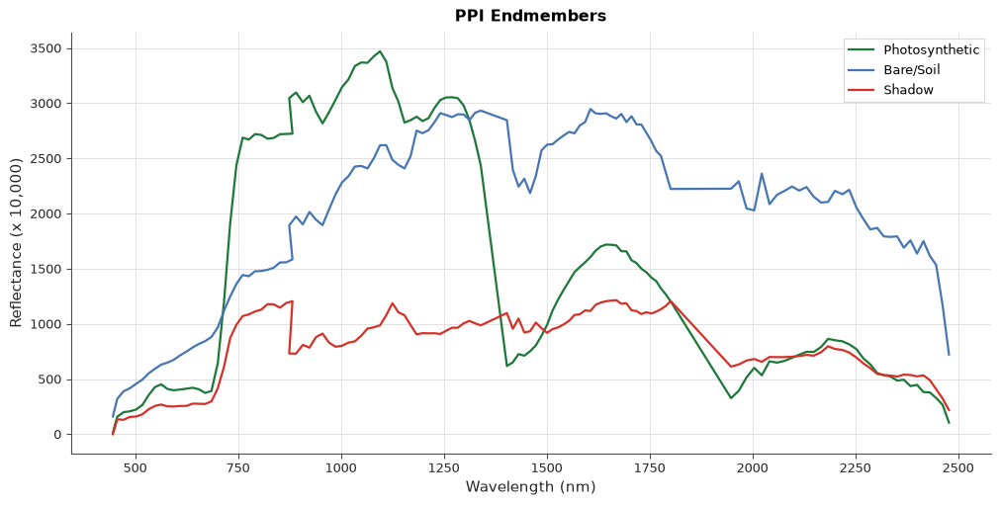

In [17]:
# Plot Endmembers
fig, ax = spectra.plot_spectra(
    {
        "Photosynthetic": photo_pxl_ppi_vals,
        "Bare/Soil": bare_pxl_ppi_vals,
        "Shadow": shadow_pxl_ppi_vals,
    },
    wavelengths=hymap_metadata["wavelength"],
    colours=list(em_colours.values()),
    title="PPI Endmembers",
    y_label="Reflectance (x 10,000)",
    figsize=(10, 5),
)

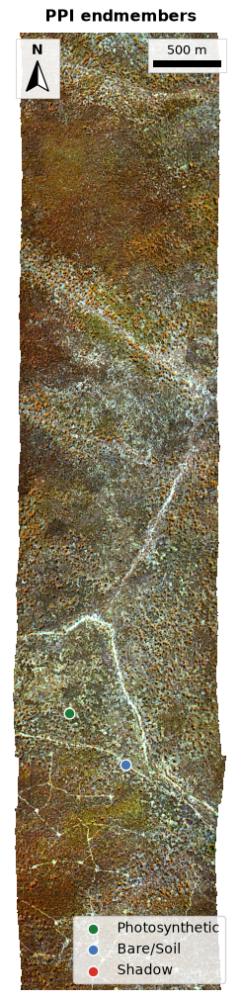

In [18]:
# Plot the Endmember locations on a map
# Visualise with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="PPI endmembers",
        )
    ],
    figsize=(5, 10),
)
for (em_name, em_clr), x_coord, y_coord in zip(em_colours.items(), x_coords, y_coords):
    axs[0].scatter(x_coord, y_coord, label=em_name, color=em_clr, edgecolor="white", s=60, zorder=5)
leg = axs[0].legend(loc="lower right")

# 4. Setting Up Spectral Unmixing

For this analysis we will use the endmembers identified through the PPI analysis, but we will also use the spectrally smoothed HyMap output for this analysis.


## 4.1 Create Valid Mask

As in notebook 2, the valid mask is a thematic image with a class name, colour and statistics, set with `set_thematic_classes` (no raster attribute table).

In [19]:
vld_msk_img = os.path.join(out_dir, "hymap_injune_subset_vld_msk.tif")

rsgispy.imageutils.masking.gen_valid_mask(
    input_img, vld_msk_img, gdalformat="GTIFF", no_data_val=0.0, calc_stats=False
)

# It is a thematic image: define it as such, with a class name and colour,
# and populate the statistics and pyramids.
rsgispy.imageutils.colourtable.set_thematic_classes(vld_msk_img, {1: ("Valid", "#2C7BB6")})

  0%|          | 0/33 [00:00<?, ?it/s]

## 4.2 Smoothing HyMap Spectra

In [20]:
spec_smooth_img = os.path.join(out_dir, "hymap_injune_subset_smoothed.tif")

rsgispy.imagespectral.preprocessing.spectral_smoothing(
    input_img,
    spec_smooth_img,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    win_len=5,
    polyorder=3,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_16INT,
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

The Savitzky-Golay filter can overshoot where the reflectance is very low (e.g., the blue bands in shadow), giving smoothed values of 0 or less. The rsgispy unmixing functions do not unmix pixels with a value `<= 0` in any band (these are not valid reflectance, and 0 is the image's no data value), so those pixels would be left as no data. Therefore, the smoothed values of the valid pixels are clipped to a minimum of 1 (i.e., 0.0001 reflectance) using `band_maths`, with one output band per input band.

In [21]:
spec_smooth_clip_img = os.path.join(out_dir, "hymap_injune_subset_smoothed_clip.tif")

n_bands = rsgispy.imageutils.metadata.get_img_band_count(spec_smooth_img)
band_defns = [rsgispy.imagecalc.maths.BandDefn("vld", vld_msk_img, 1)]
band_defns += [
    rsgispy.imagecalc.maths.BandDefn("b{}".format(n), spec_smooth_img, n)
    for n in range(1, n_bands + 1)
]
# One expression per output band: max(bN, 1) within the valid mask, else 0.
exp = ", ".join(["vld == 1 ? max(b{}, 1) : 0".format(n) for n in range(1, n_bands + 1)])
rsgispy.imagecalc.maths.band_maths(
    spec_smooth_clip_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_16INT,
    no_data_val=0,
    calc_stats=True,
)
# Use the clipped image from here on.
spec_smooth_img = spec_smooth_clip_img

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

## 4.3 Extract Endmembers

The first step in undertaking a spectral unmixing is to extract the spectra being used for the analysis. `extract_avg_endmembers` calculates the mean spectrum of the pixels within each polygon (here the three polygons in `hymap_ppi_endmembers.geojson`, which were digitised using the PPI analysis above) and returns them as a pandas DataFrame, with a row per band and a column per endmember. The rsgispy unmixing functions accept this DataFrame directly, or a file it has been saved to (here a CSV file).

**RSGISLib users:** endmembers are now a pandas DataFrame (or a CSV, Excel, Parquet or `.mtxt` file); the RSGISLib `.mtxt` format can still be read with `rsgispy.imagespectral.endmembers.read_endmembers_df`.

In [22]:
vec_file = "../data/hymap_ppi_endmembers.geojson"

endmember_file = os.path.join(out_dir, "hymap_ppi_endmembers.csv")

endmembers_df = rsgispy.imagespectral.endmembers.extract_avg_endmembers(
    spec_smooth_img,
    vec_file,
    out_file=endmember_file,
    endmember_names=["Photosynthetic", "Bare_Soil", "Shadow"],
    all_touched=False,  # use the pixels whose centre is inside a polygon
)
endmembers_df.head()

,Photosynthetic,Bare_Soil,Shadow
band,,,
band_1,111.00,851.000000,7.50
band_2,207.50,926.181818,30.25
band_3,253.00,1025.454545,58.25
band_4,271.25,1122.818182,76.25
band_5,293.25,1212.545455,81.50


## 4.4 Plot Endmembers File

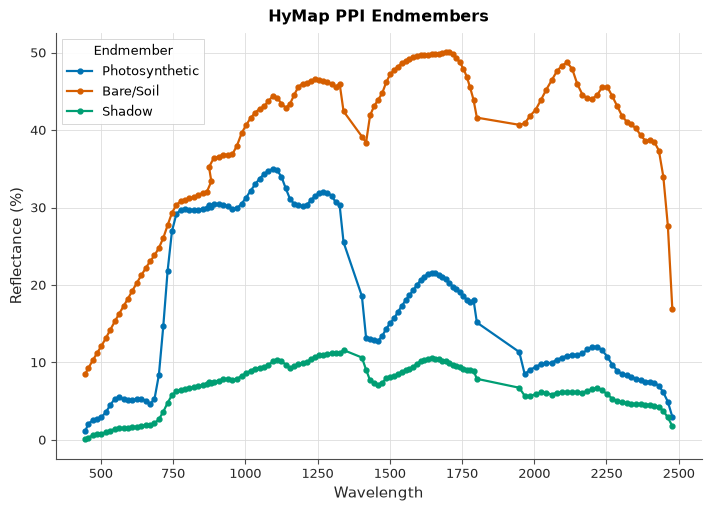

In [23]:
out_plot_file = os.path.join(out_dir, "hymap_ppi_endmembers_plot.png")
endmember_names = ["Photosynthetic", "Bare/Soil", "Shadow"]
# A gain of 100 converts the image values (x 10,000) to reflectance (%).
# The plot is shown and also saved to out_plot_file.
fig, ax = rsgispy.imagespectral.endmembers.plot_endmembers(
    endmembers_df,
    endmember_names=endmember_names,
    plot_title="HyMap PPI Endmembers",
    gain=100,
    wavelengths=hymap_metadata["wavelength"],
    y_label="Reflectance (%)",
    out_plot_file=out_plot_file,
)

The endmembers can also be marked on the feature space (`points=`, in image units), to see where they lie relative to the edges of the data. The photosynthetic endmember is on the high NIR, low red edge of the NIR v Red feature space, the shadow endmember is in the dark corner (close to the origin) and the bare/soil endmember is at the bright end of the data (the top corner of the NIR v SWIR feature space). Here the NIR v Red and NIR v SWIR feature spaces are drawn side by side by passing an axis (`ax=`) to each plot:

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

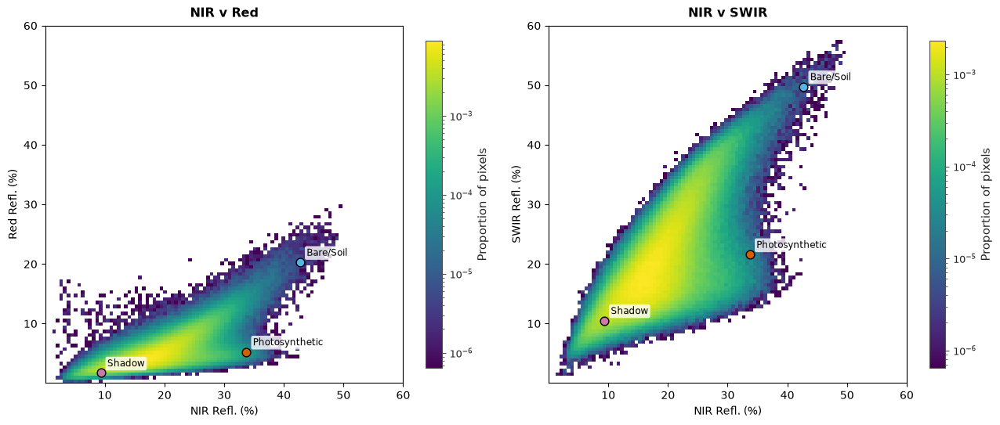

In [24]:
# Value of each endmember in a band (the endmembers DataFrame has a row per band)
def em_band_vals(band):
    return endmembers_df.loc["band_{}".format(band)].to_numpy()


fig, axs = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (y_band, y_label) in zip(axs, [(13, "Red Refl. (%)"), (81, "SWIR Refl. (%)")]):
    em_points = dict(zip(endmember_names, zip(em_band_vals(42), em_band_vals(y_band))))
    rsgispy.tools.plotting.plot_2d_img_histogram(
        input_img,
        x_band=42,
        y_band=y_band,
        bins=100,
        x_range=(1, 6000),
        y_range=(1, 6000),
        val_scale=100,
        x_label="NIR Refl. (%)",
        y_label=y_label,
        title="NIR v {}".format(y_label.split()[0]),
        points=em_points,
        ax=ax,
    )
fig.tight_layout()

# 5. Simple Unconstrained Unmixing

The simplest and fastest way to perform an unmixing it to run an unconstrained model and then rescale the values to meet the required constrains (i.e., non-negative and sum to 1). This analysis is shown below:

**RSGISLib users:** rsgispy has its own vectorised solvers (`spec_unmix_ucls`, `spec_unmix_nnls` and `spec_unmix_fcls`), which are recommended over the `spec_unmix_spts_*` versions (which wrap pysptools) and are much faster - the fully constrained unmixing below takes seconds rather than minutes. The endmembers argument comes before the (optional) valid mask.

In [25]:
spec_unmix_ucls_img = os.path.join(out_dir, "hymap_injune_subset_ucls.tif")
rsgispy.imagespectral.unmixing.spec_unmix_ucls(
    spec_smooth_img,
    spec_unmix_ucls_img,
    endmembers_df,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    gain=1,
    weight=None,
    gdalformat="GTIFF",
    calc_stats=True,
)

spec_unmix_ucls_scale_img = os.path.join(out_dir, "hymap_injune_subset_ucls_scale.tif")
rsgispy.imagespectral.unmixing.rescale_unmixing_results(
    spec_unmix_ucls_img, spec_unmix_ucls_scale_img, gdalformat="GTIFF", calc_stats=True
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

You’ll find two output images in `outputs/unmixing`:

 * hymap_injune_subset_ucls.tif
 * hymap_injune_subset_ucls_scale.tif

If you open these two images (in QGIS or TuiView; note you might find it most useful to open them in two geo-linked viewers) you will see that the first image (before rescaling) has quite a lot of fine scale detail while some of this is removed through the rescaling. This is in part as negative values are assigned to 0 during the rescaling. 

Note, from the terminal (in the `outputs/unmixing` directory) you can open the two images in separate geo-linked TuiView viewers using the following command:

```
tuiview --separate hymap_injune_subset_ucls.tif hymap_injune_subset_ucls_scale.tif
```

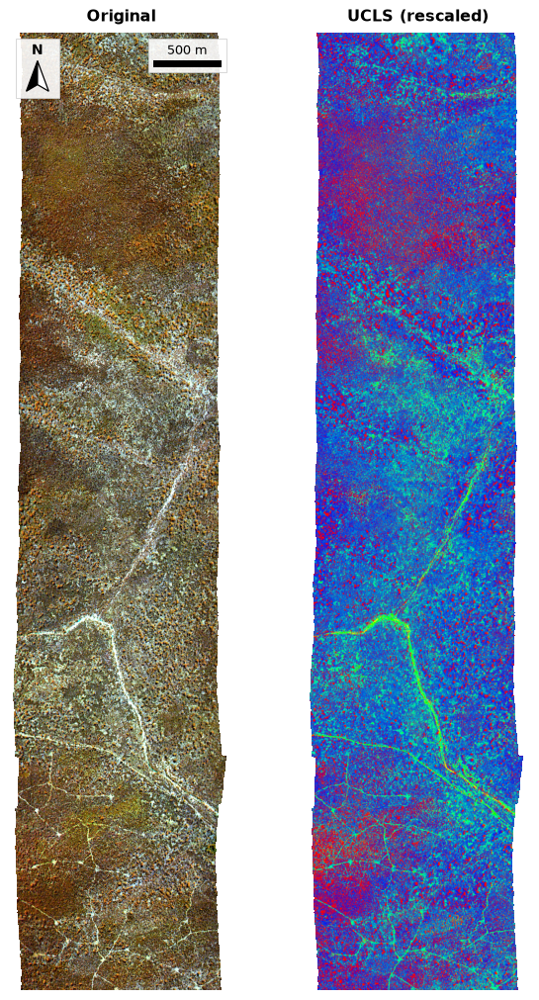

In [26]:
# Visualise the original image with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
# and the unmixing results with the abundances of the three endmembers as RGB
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_ucls_scale_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="UCLS (rescaled)", map_kw={"no_data_val": -9999},
        ),
    ],
    figsize=(6, 10),
)

# 6. Non-Negative Constraint Unmixing

For a fully constrained unmixing the proportions must sum to 1 with no negative values. These conditions can be difficult to meet together but by using non-negative least squares (NNLS) to compute the model we can ensure that the resulting abundances are positive and once rescaled will also sum to 1, meeting both constraints:

In [27]:
spec_unmix_nnls_img = os.path.join(out_dir, "hymap_injune_subset_nnls.tif")
rsgispy.imagespectral.unmixing.spec_unmix_nnls(
    spec_smooth_img,
    spec_unmix_nnls_img,
    endmembers_df,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    gain=1,
    weight=None,
    gdalformat="GTIFF",
    calc_stats=True,
)

spec_unmix_nnls_scale_img = os.path.join(out_dir, "hymap_injune_subset_nnls_scale.tif")
rsgispy.imagespectral.unmixing.rescale_unmixing_results(
    spec_unmix_nnls_img, spec_unmix_nnls_scale_img, gdalformat="GTIFF", calc_stats=True
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

Again, view these images within QGIS or TuiView and look at the pixel values and consider the difference between the two (i.e., the rescaled image sums to 1).


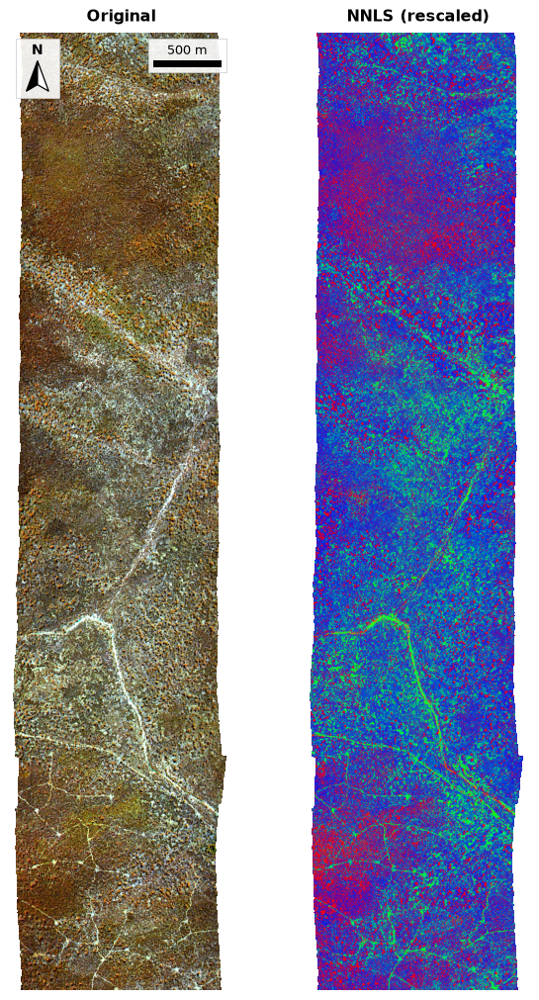

In [28]:
# Visualise the original image with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
# and the unmixing results with the abundances of the three endmembers as RGB
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_nnls_scale_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="NNLS (rescaled)", map_kw={"no_data_val": -9999},
        ),
    ],
    figsize=(6, 10),
)

Alternatively, rather than rescaling the values we can use a weight, as outlined by Scarth et al. (2010), whether a constant weight is added to both the endmembers and image spectra as an extra band and by (experimentally) optimising this value we can constrain the model to sum to 1.

In [29]:
spec_unmix_nnls_wt_img = os.path.join(out_dir, "hymap_injune_subset_nnls_wt.tif")
rsgispy.imagespectral.unmixing.spec_unmix_nnls(
    spec_smooth_img,
    spec_unmix_nnls_wt_img,
    endmembers_df,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    gain=10000,
    weight=1000,
    gdalformat="GTIFF",
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

Now, compare the results of the NNLS rescaled analysis and NNLS weighted analysis:

 * hymap_injune_subset_nnls_scale.tif
 * hymap_injune_subset_nnls_wt.tif

```
tuiview --separate hymap_injune_subset_nnls_scale.tif hymap_injune_subset_nnls_wt.tif
```

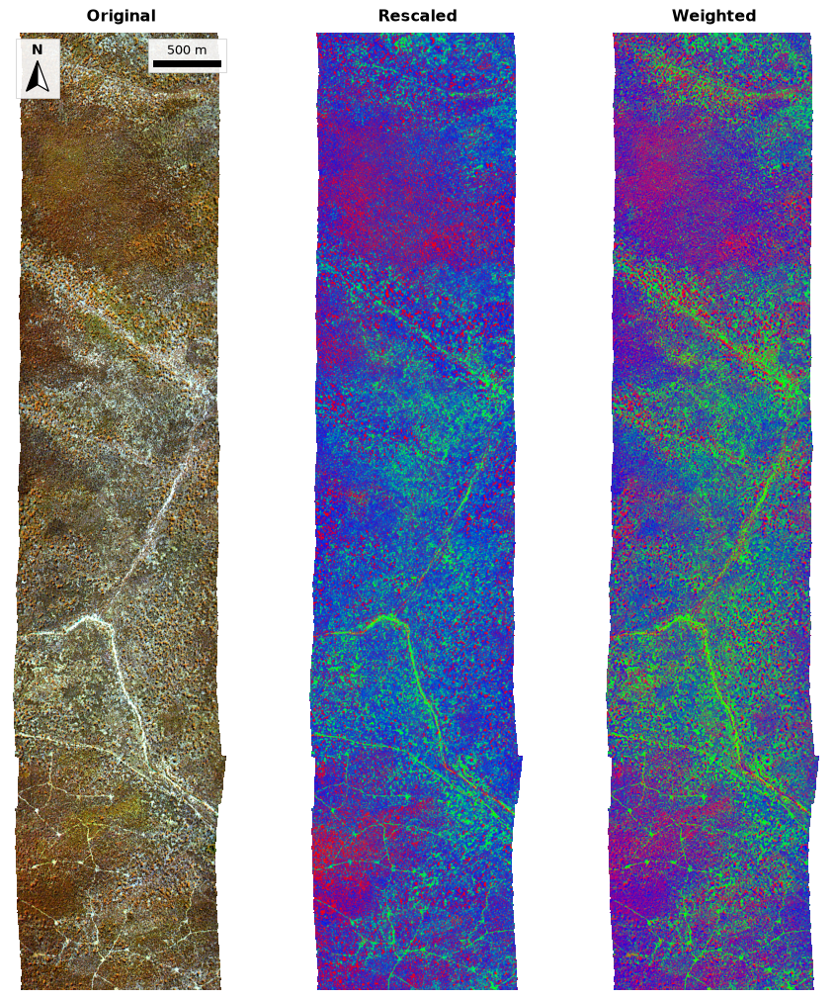

In [30]:
# Visualise the original image with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
# and the unmixing results with the abundances of the three endmembers as RGB
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_nnls_scale_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="Rescaled", map_kw={"no_data_val": -9999},
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_nnls_wt_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="Weighted", map_kw={"no_data_val": -9999},
        ),
    ],
    figsize=(9, 10),
)

If you want to see the effect of the weight try changing this parameter, for example:

 * 10
 * 100
 * 1000
 * 10000
 * 100000
 * 1000000


In [31]:
wts = [10, 100, 1000, 10000, 100000, 1000000]
for wt in wts:
    spec_unmix_nnls_wt_img = os.path.join(
        out_dir, "hymap_injune_subset_nnls_wt_{}.tif".format(wt)
    )
    rsgispy.imagespectral.unmixing.spec_unmix_nnls(
        spec_smooth_img,
        spec_unmix_nnls_wt_img,
        endmembers_df,
        valid_msk_img=vld_msk_img,
        valid_msk_val=1,
        gain=1,
        weight=wt,
        gdalformat="GTIFF",
        calc_stats=True,
        use_pbar=False,
    )

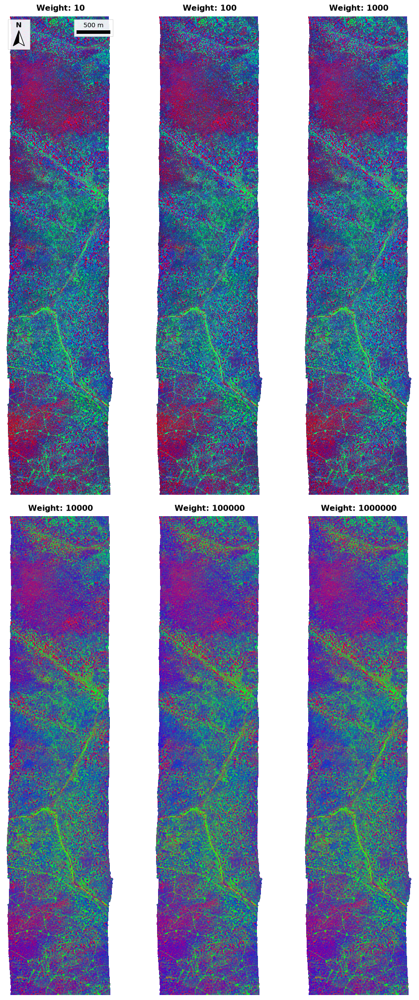

In [32]:
wt_panels = []
for wt in wts:
    spec_unmix_nnls_wt_img = os.path.join(
        out_dir, "hymap_injune_subset_nnls_wt_{}.tif".format(wt)
    )
    wt_panels.append(
        map_layout.MapPanel(
            "rgb", spec_unmix_nnls_wt_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="Weight: {}".format(wt), map_kw={"no_data_val": -9999},
        )
    )

fig, axs = map_layout.create_map_panels(wt_panels, ncols=3, figsize=(9, 20))

Note. the weight is relative to the scale of the image values so note, the gain value was changed (to 1) to help illustrate the effect of the weight parameter. Given the HyMap data has been multiplied by 10,000, then a gain of 10,000, as used earlier and is the correct value to use as it rescales the data to a range of 0 – 1 for the unmixing. Hence you get a different result for the weight 1000. 

You can easily open all the images in different TuiView windows (from the `outputs/unmixing` directory) using the following command:

```
tuiview --separate hymap_injune_subset_nnls_wt_*.tif
```


# 7. Fully Constrained Unmixing

As you’ll have seen, using the weighted NNLS result directly produces a fully constrained linear unmixing of the data but there are other approaches, which use different optimisation algorithms and doesn’t require the weight parameter to be optimised. The `spec_unmix_fcls` function in rsgispy solves the fully constrained (non-negative and sum-to-one) problem directly, and takes only a few seconds for this image. (The pysptools-based `spec_unmix_spts_fcls` gives very similar abundances but takes around 5 minutes.)

In [33]:
spec_unmix_fcls_img = os.path.join(out_dir, "hymap_injune_subset_fcls.tif")
rsgispy.imagespectral.unmixing.spec_unmix_fcls(
    spec_smooth_img,
    spec_unmix_fcls_img,
    endmembers_df,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    gain=10000,
    gdalformat="GTIFF",
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

Once, you have this output compare it to the NNLS weighted output. How much difference do you notice? Is there much difference in the abundances generated?

 * hymap_injune_subset_fcls.tif
 * hymap_injune_subset_nnls_wt.tif


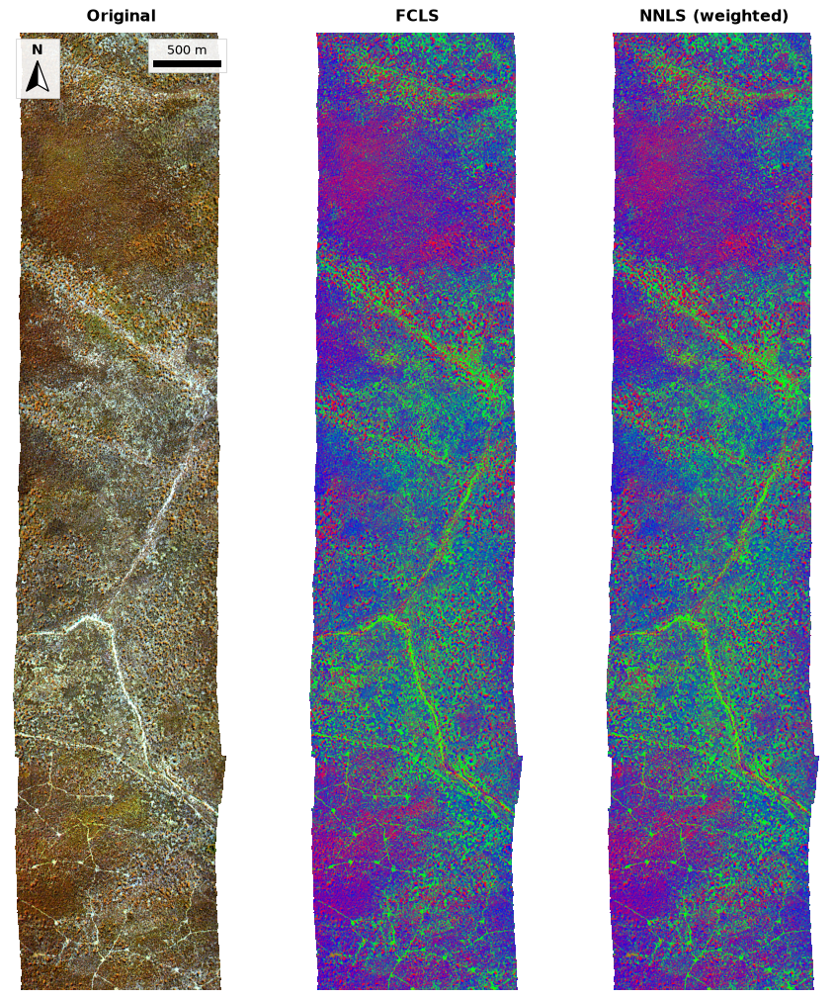

In [34]:
# The FCLS and the (gain = 10,000, weight = 1000) NNLS results
spec_unmix_nnls_wt_img = os.path.join(out_dir, "hymap_injune_subset_nnls_wt.tif")

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_fcls_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="FCLS", map_kw={"no_data_val": -9999},
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_nnls_wt_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="NNLS (weighted)", map_kw={"no_data_val": -9999},
        ),
    ],
    figsize=(9, 10),
)

# 8. Recomputing a reflectance image from the endmembers and abundances

In [35]:
pred_refl_img = os.path.join(out_dir, "hymap_injune_subset_pred_refl.tif")
rsgispy.imagespectral.unmixing.predict_refl_linear_unmixing(
    spec_unmix_fcls_img,
    pred_refl_img,
    endmembers_df,
    gdalformat="GTIFF",
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

Open the resulting image and what do you noticed when compared to the original image?

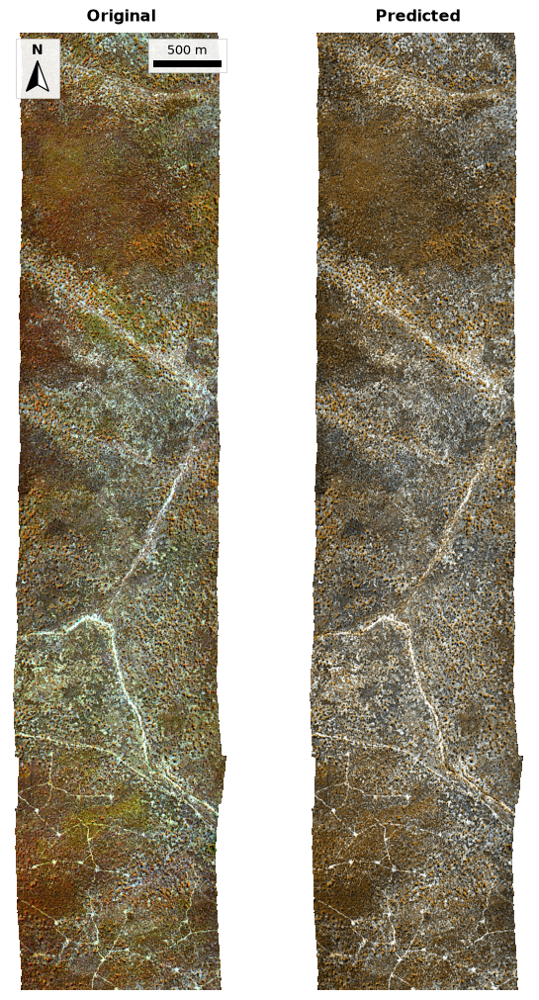

In [36]:
# Visualise both with bands 32 (NIR), 19 (Red Edge) and 1 (Blue)
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", pred_refl_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Predicted",
        ),
    ],
    figsize=(6, 10),
)

# 9. Calculating Error to Original

If we can reproduce something similar to the original image, then we can calculate the error between the original image and the predicted. This can be useful for comparing different approaches and endmembers providing a numeric way of comparing how well an unmixing and endmembers can represent the original image. The following scripts calculating the root mean square error (RMSE) and the residual on a per-pixel basis:

In [37]:
unmix_rmse_img = os.path.join(out_dir, "hymap_injune_subset_unmix_rmse.tif")
rsgispy.imagespectral.unmixing.calc_unmixing_rmse_residual_err(
    input_img,
    spec_unmix_fcls_img,
    unmix_rmse_img,
    endmembers_df,
    gdalformat="GTIFF",
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

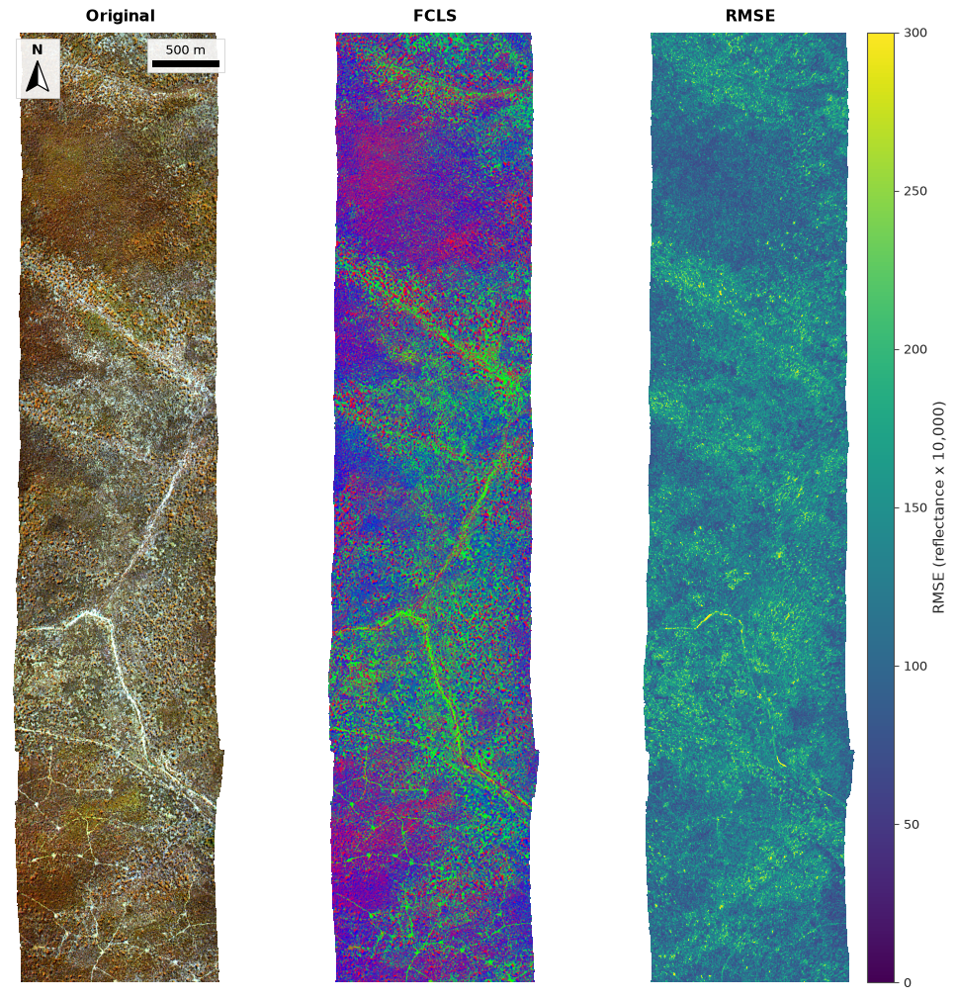

In [38]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", spec_unmix_fcls_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="FCLS", map_kw={"no_data_val": -9999},
        ),
        map_layout.MapPanel(
            "cmap", unmix_rmse_img, bands=1, cmap_name="viridis",
            vmin=0, vmax=300, show_colour_bar=True,
            cbar_label="RMSE (reflectance x 10,000)", title="RMSE",
        ),
    ],
    figsize=(10, 10),
)

# 10. Summary

Most of the time we are not undertaking hyperspectral data analysis, however that does not mean that these methods are not relevant for other some multispectral dataset or problems. Therefore, somethings to take away from this analysis:

 * Spectral unmixing can be a powerful technique and work really well on multispectral data. For example, the analysis of Ettritch et al., (2018) using landsat 
 * Image classification is clearly a massive topic and is a common analysis which is performed on hyperspectral data. We haven’t covered it here as you have already done a lot of image classification work. Machine learning approaches of classification are commonly applied to hyperspectral data but do consider the high amount of correlation between your image bands. There are also approaches specifically tailored to hyperspectral data analysis such as spectral angle mapper and spectral correlation mapper (see `rsgispy.imagespectral.classification`).
 * PCA and other dimensionality reduction methods can be applied in a wide range of applications. For example, reducing and combining variables which are highly correlated from a classification or regression analysis, such as habitat suitability modelling.
